# Hauptexperiment I: QA-basierte Faktenretention

## Eingaben und Ausgaben

Nach der einmaligen Vorbereitung mit `python 05_analyze.py --prepare` genügt **Run All**.
Die folgende Zelle zeigt Daten, Vorgängertabellen und neue Ausgaben. `DATA_DIR` und
`OUTPUT_DIR` dürfen auf eigene absolute Verzeichnisse zeigen. `TABLES` liest standardmäßig
die vorbereiteten historischen Tabellen; für selbst neu erzeugte Vorgängertabellen
kann hier `OUTPUT_DIR / "tables"` stehen. Eingaben und neue Ausgaben bleiben getrennt.


In [1]:
from pathlib import Path
from faktenretention.paths import PROJECT_ROOT
from faktenretention.notebook_context import setup_notebook
from faktenretention.io import relative_path, sha

# Hier können eigene absolute Daten- und Ausgabeverzeichnisse stehen.
DATA_DIR = PROJECT_ROOT / "data/prepared"
OUTPUT_DIR = PROJECT_ROOT / "results/notebooks"
# Historische Vorgängertabellen; für eigene Neuberechnungen OUTPUT_DIR / "tables" einsetzen.
TABLES = DATA_DIR / "tables"
setup_notebook(DATA_DIR, OUTPUT_DIR)
OUT = OUTPUT_DIR / "tables/03_qa_retention"
FIG = OUTPUT_DIR / "figures/03_qa_retention"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Eingaben:", DATA_DIR / "qa")
print("Vorgängertabellen:", TABLES)
print("Neue Tabellen:", OUT)
print("Neue Grafiken:", FIG)


Eingaben: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/qa
Vorgängertabellen: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/tables
Neue Tabellen: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/tables/03_qa_retention
Neue Grafiken: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/figures/03_qa_retention


**Ziel dieses Notebooks**

Dieses Notebook hat als Ziel die Forschungsfragen **F1** und **F2** zu beantworten.

Dabei geht es zum einen um die Faktenretention entlang der rekursiven Kompressionskette und zum anderen um den gepaarten Methodenvergleich verschiedener Methodenpaare.

Die Auswertung wird vollständig aus gespeicherten Einzelantworten neu berechnet. Es erfolgen keine neuen Modellaufrufe. Der kanonische Faktensatz bleibt über alle Methoden und Stufen gleich. Technisch fehlende QA-Urteile werden separat geführt. Bootstrap-Einheit ist der **Artikel**, nicht die einzelne Frage oder Zusammenfassung.

Die tatsächliche Wortlänge und längenadjustierte Retention gehören in die folgenden Auswertungen. Die hier berichteten Unterschiede gelten für die erzeugten Texte bei denselben **Zielwortzahlen**, nicht zwingend derselben tatsächlichen Länge.

In [2]:
from pathlib import Path
from collections import Counter
import gzip, hashlib, importlib.util, importlib.metadata, json, platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

BASE = DATA_DIR
DATA = DATA_DIR / "qa"
VERSION = "aktuell_20260930"  # alternativ: "original_frozen"
SEED, B = 32, 10_000
from faktenretention.protocol import METHODS
from faktenretention.protocol import STAGES
N_FACTS = 20
from faktenretention.protocol import LABELS as LABELS
from faktenretention.protocol import CONTRASTS
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = dict(zip(METHODS, ["#777777", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))
MARKERS = dict(zip(METHODS, ["o", "s", "^", "D", "v", "P"]))
LINESTYLES = dict(zip(METHODS, ["--", "-", "-.", "--", ":", "-"]))

def read(name, version=VERSION):
    return pd.read_csv(DATA / version / name, keep_default_na=False, low_memory=False)

def savefig(fig, name):
    for ext in ["png", "svg", "pdf"]:
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def export(frame, name):
    frame.to_csv(OUT / f"{name}.csv", index=False)

def fmt(x):
    return f"{x:.1f}".replace(".", ",")

manifest = json.loads((DATA / "source_manifest.json").read_text())
for entry in manifest["files"]:
    file = DATA / entry["file"]
    assert hashlib.sha256(file.read_bytes()).hexdigest() == entry["sha256"], file
    if file.suffix == ".gz":
        assert hashlib.sha256(gzip.decompress(file.read_bytes())).hexdigest() == entry["original_sha256"], file
from faktenretention import scoring as scorer
versions = {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "matplotlib", "nbformat", "nbclient"]}
display(Markdown(f"**Version:** `{VERSION}` · **Bootstrap:** {B:,} Artikelstichproben, Seed {SEED}."))
display(pd.DataFrame([{"Komponente": "Python", "Version": platform.python_version()}] +
                     [{"Komponente": k, "Version": v} for k, v in versions.items()]))


**Version:** `aktuell_20260930` · **Bootstrap:** 10,000 Artikelstichproben, Seed 32.

,Komponente,Version
0,Python,3.13.15
1,numpy,2.5.4
2,pandas,3.0.6
3,matplotlib,3.11.2
4,nbformat,5.11.1
5,nbclient,0.11.0


## 1. Datenbasis

100 CNN/DailyMail-Testartikel werden mit sechs Methoden rekursiv auf die Zielstufen 500 → 300 → 150 → 75 Wörter verdichtet. Je Artikel werden dieselben 20 kanonischen Fakten aus dem Original geprüft: **2.000 unterschiedliche Fakten**, **2.400 Zusammenfassungspositionen** und **48.000 wiederholte QA-Positionen**. Die 48.000 Positionen sind keine unabhängigen Versuchseinheiten.

Die historische Human-QA-Validierung diente der Entwicklung der Antwortinstruktion und der generalisierten lexikalischen Scorer-Kalibrierung. Hier wird genau der gespeicherte Scorer angewendet; es erfolgt keine Anpassung an die Hauptexperiment-Ergebnisse. Die dort ermittelte Übereinstimmung ist eine Kalibrierungsdiagnose auf Entwicklungsfällen und keine geschätzte Fehlerrate der finalen Pipeline. Der finale Faktensatz, der QA-Antworter und die Belegprüfung unterscheiden sich von der historischen Validierung.

Zusammenfasser: `thesis-seed:v1`; Faktengenerator: `thesis-gemma:v1`; QA-Antworter: `thesis-qwen38-qa:v1`. 
Die Evaluation verwendet Temperatur 0 und Seed 32. Der Faktensatz enthält 20 kanonische Fakten je Artikel aus einem Pool von 24 Kandidaten; die Analyse misst die Retention dieses ausgewählten Satzes und nicht die Vollständigkeit aller Informationen im Artikel.

## 2. Reproduktion der automatischen Labels und Missingness

Die Funktionen zur Antwortnormalisierung und Kalibrierung wurden unverändert aus dem lokalen Scorer übernommen; der vollständige Quelltext liegt im Datenpaket. Nicht fehlende Antworten werden als `retained`, `lost` (`NOT_FOUND`) oder `reference_discordant` bewertet. Für technisch fehlende Urteile wird **kein inhaltliches Label** vergeben.

In [5]:
qa["technical_missing"] = qa.error.astype(str).ne("")
qa["analysis_eligible"] = ~qa.technical_missing
qa["grounded"] = [scorer.support_is_grounded(s, a, e) for s, a, e in zip(qa.summary, qa.answer, qa.support)]
assert qa.loc[qa.analysis_eligible, "grounded"].all()
assert qa.loc[qa.analysis_eligible, "answer"].str.strip().ne("").all()
qa["retained"] = [scorer.retained(ref, ans) if ok else False for ref, ans, ok in
                  zip(qa.reference_answer, qa.answer, qa.analysis_eligible)]
qa["lost"] = qa.analysis_eligible & qa.answer.str.upper().eq("NOT_FOUND")
qa["reference_discordant"] = qa.analysis_eligible & ~qa.retained & ~qa.lost
qa["label"] = np.select([qa.technical_missing, qa.retained, qa.lost, qa.reference_discordant],
                        ["technical_missing", "retained", "lost", "reference_discordant"], default="INVALID")
assert not qa.label.eq("INVALID").any()
qa["retention_value"] = np.where(qa.analysis_eligible, qa.retained.astype(float), np.nan)
check = qa[KEY + ["analysis_eligible", "technical_missing", "retained", "lost", "reference_discordant"]].merge(
    archived[KEY + ["analysis_eligible", "technical_missing", "retention", "loss", "reference_discordant_answer"]],
    on=KEY, suffixes=("", "_archive"), validate="one_to_one")
for local, stored in [("analysis_eligible", "analysis_eligible_archive"), ("technical_missing", "technical_missing_archive")]:
    assert check[local].eq(check[stored].astype(str).str.lower().eq("true")).all(), local
for local, stored in [("retained", "retention"), ("lost", "loss"), ("reference_discordant", "reference_discordant_answer")]:
    valid = check.analysis_eligible
    assert check.loc[valid, local].eq(check.loc[valid, stored].astype(str).str.lower().eq("true")).all(), local
    assert check.loc[~valid, stored].astype(str).eq("").all(), stored
status = qa.groupby(["method", "stage_target_words"]).agg(
    n_expected=("canonical_fact_id", "size"), n_valid=("analysis_eligible", "sum"),
    n_missing=("technical_missing", "sum"), n_synthetic_not_found=("empty_output", "sum"), n_retained=("retained", "sum"),
    n_lost=("lost", "sum"), n_reference_discordant=("reference_discordant", "sum")).reset_index()
status["missing_percent"] = 100 * status.n_missing / status.n_expected
assert (status.n_retained + status.n_lost + status.n_reference_discordant + status.n_missing).eq(status.n_expected).all()
export(status, "qa_status_methoden_stufen")
display(status)
display(qa.groupby(["answer_status", "error", "label"], dropna=False).size().rename("QA-Positionen").reset_index())
display(Markdown(f"**{qa.analysis_eligible.sum():,}/{len(qa):,} gültige Urteile; {qa.technical_missing.sum():,} technisch fehlend ({fmt(100*qa.technical_missing.mean())} %).**"))


,method,stage_target_words,n_expected,n_valid,n_missing,n_synthetic_not_found,n_retained,n_lost,n_reference_discordant,missing_percent
0,auto_cot,75,2000,1998,2,0,781,983,234,0.10
1,auto_cot,150,2000,1987,13,0,1153,565,269,0.65
2,auto_cot,300,2000,1989,11,0,1356,382,251,0.55
3,auto_cot,500,2000,1988,12,0,1419,329,240,0.60
4,automate_cot,75,2000,1995,5,0,738,1033,224,0.25
5,automate_cot,150,2000,1991,9,0,1074,662,255,0.45
6,automate_cot,300,2000,1984,16,0,1371,374,239,0.80
7,automate_cot,500,2000,1989,11,0,1460,312,217,0.55
8,few_shot_cot,75,2000,1992,8,0,688,1078,226,0.40
9,few_shot_cot,150,2000,1985,15,0,1008,714,263,0.75


,answer_status,error,label,QA-Positionen
0,answered,,reference_discordant,5172
1,answered,,retained,25074
2,answered,support_not_exactly_grounded_in_summary,technical_missing,196
3,not_found,,lost,17558


**47,804/48,000 gültige Urteile; 196 technisch fehlend (0,4 %).**

## 3. Bootstrap auf Artikelebene

Für jede Schätzung werden 10.000 Artikelstichproben mit Zurücklegen gezogen (NumPy `default_rng`, Seed 32). Ein gezogener Artikel bringt seine gesamte betrachtete Methoden-/Stufenstruktur mit. Für einen Methodenvergleich werden zuerst die beiden Artikelwerte subtrahiert und diese **gepaarten Differenzen** resampelt. Für die 100-Artikel-Hauptauswertung verwenden alle Mittelwerte, Stufenänderungen und Kontraste dieselbe Ziehungsmatrix.

Bei Sensitivitäten mit anderen Artikelmengen wird die jeweilige sortierte Artikelmenge mit Seed 32 und ihrer eigenen Größe resampelt. Identische Mengen verwenden wieder dieselbe Matrix. Berichtet werden Mittelwerte und die 2,5-/97,5-Perzentile der Bootstrap-Verteilung, also **punktweise** 95-%-Intervalle. Die Monte-Carlo-Ziehungen können von den archivierten, mit mehreren abgeleiteten Seeds berechneten Intervallen abweichen; die Punktschätzer wurden zuvor exakt reproduziert.

Die Intervalle erfassen Artikelheterogenität unter den fest vorliegenden Texten, Fakten und QA-Urteilen. Sie erfassen weder die Fehlklassifikation des QA-Scorers noch die Variation neuer Modellläufe. Die Interpretation über diese 100 Artikel hinaus setzt eine geeignete Artikelauswahl voraus.

In [7]:
index_cache = {}
from faktenretention.statistics import estimate

from faktenretention.statistics import means_for

means = means_for(article)
means_percent = means.assign(mean_percent=100*means["mean"], ci_low_percent=100*means.ci_low,
                             ci_high_percent=100*means.ci_high)
export(means_percent, "retention_mittelwerte_95ci")
mean_table = means.assign(method=lambda d: d.method.map(LABELS),
    Ergebnis=lambda d: [f"{fmt(100*r.mean)} [{fmt(100*r.ci_low)}; {fmt(100*r.ci_high)}]; n={r.n_articles}" for r in d.itertuples()])
display(mean_table.pivot(index="method", columns="stage_target_words", values="Ergebnis").reindex(index=list(LABELS.values()), columns=STAGES))


stage_target_words,500,300,150,75
method,,,,
Lead-k,"75,6 [72,8; 78,3]; n=100","49,4 [46,7; 52,0]; n=100","30,2 [28,0; 32,5]; n=100","17,3 [15,6; 19,1]; n=100"
Plain,"54,9 [51,5; 58,1]; n=100","50,0 [46,7; 53,3]; n=100","45,1 [41,9; 48,3]; n=100","33,8 [30,9; 36,7]; n=100"
Zero-Shot-CoT,"71,9 [69,1; 74,6]; n=100","67,9 [65,1; 70,5]; n=100","53,6 [50,5; 56,7]; n=100","28,9 [26,1; 31,8]; n=100"
Few-Shot-CoT,"64,2 [61,2; 67,0]; n=100","61,0 [58,1; 64,0]; n=100","50,8 [47,7; 53,8]; n=100","34,6 [31,7; 37,5]; n=100"
Auto-CoT,"71,3 [68,6; 73,9]; n=100","68,2 [65,4; 70,8]; n=100","58,0 [54,9; 61,0]; n=100","39,1 [36,4; 41,7]; n=100"
Automate-CoT,"73,4 [70,6; 76,1]; n=100","69,1 [66,3; 71,8]; n=100","54,0 [50,7; 57,1]; n=100","37,0 [34,1; 39,9]; n=100"


## 4. F1: Verlauf über die Kompressionsstufen

Folgend werden Grafiken zur behandlung der Forschungsfrage F1 berechnet. Dabei geht es um die entwicklung der Faktenretention entlang der rekursiven Kompressionskette. bei 100% Faktenretention konnten alle Ausgangsfakten durch eine Zusammenfassung korrekt beantwortet werdenm, bei 0% wurde keine der Ausgangsfakten korrekt beantwortet. Die vertikalen Balken der punkte sind Bootstrap-Intervalle.

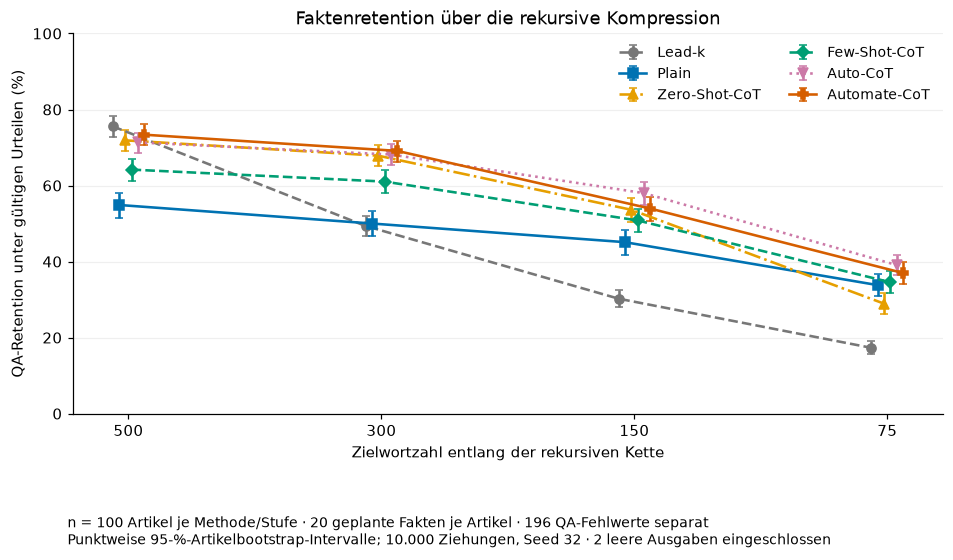

,method,transition,from_stage,to_stage,n_articles,mean,ci_low,ci_high,n_increase,n_equal,n_decrease
0,lead_k,500→300,500,300,100,-26.218421,-28.510526,-23.920921,1,0,99
1,lead_k,300→150,300,150,100,-19.126316,-21.018421,-17.247303,0,5,95
2,lead_k,150→75,150,75,100,-12.934211,-14.634276,-11.313158,0,10,90
3,lead_k,500→75,500,75,100,-58.278947,-60.878947,-55.592105,0,0,100
4,plain,500→300,500,300,100,-4.880994,-6.456155,-3.405526,8,39,53
5,plain,300→150,300,150,100,-4.902047,-6.426082,-3.498787,2,52,46
6,plain,150→75,150,75,100,-11.308187,-13.787105,-8.981455,2,27,71
7,plain,500→75,500,75,100,-21.091228,-23.979569,-18.293246,1,5,94
8,zero_shot_cot,500→300,500,300,100,-4.034795,-5.566433,-2.578860,11,41,48
9,zero_shot_cot,300→150,300,150,100,-14.221930,-16.880768,-11.755263,2,14,84


**Größter mittlerer Rückgang je Methode (deskriptive Auswahl):**

,method,transition,mean,ci_low,ci_high,n_articles
18,auto_cot,150→75,-18.928363,-21.115855,-16.800000,100
22,automate_cot,150→75,-16.963158,-18.990797,-14.923677,100
14,few_shot_cot,150→75,-16.277468,-18.335678,-14.233016,100
0,lead_k,500→300,-26.218421,-28.510526,-23.920921,100
6,plain,150→75,-11.308187,-13.787105,-8.981455,100
10,zero_shot_cot,150→75,-24.705263,-27.065921,-22.397368,100


In [10]:
fig, ax = plt.subplots(figsize=(10.2, 5.4))
x = np.arange(4)
for i, method in enumerate(METHODS):
    sub = means[means.method.eq(method)].set_index("stage_target_words").loc[STAGES]
    offset = (i - 2.5) * .025
    y = 100 * sub["mean"].to_numpy()
    err = np.vstack([y - 100*sub.ci_low.to_numpy(), 100*sub.ci_high.to_numpy() - y])
    ax.errorbar(x + offset, y, yerr=err, color=COLORS[method], marker=MARKERS[method],
                linestyle=LINESTYLES[method], linewidth=1.7, capsize=2.5, label=LABELS[method])
ax.set(xticks=x, xticklabels=STAGES, ylim=(0,100), yticks=np.arange(0,101,20),
       xlabel="Zielwortzahl entlang der rekursiven Kette", ylabel="QA-Retention unter gültigen Urteilen (%)",
       title="Faktenretention über die rekursive Kompression")
ax.grid(axis="y", alpha=.2)
ax.legend(loc="upper right", ncol=2, frameon=False, fontsize=9)
fig.subplots_adjust(bottom=.24)
fig.text(.12, .02, f"n = 100 Artikel je Methode/Stufe · 20 geplante Fakten je Artikel · {qa.technical_missing.sum()} QA-Fehlwerte separat\n"
         "Punktweise 95-%-Artikelbootstrap-Intervalle; 10.000 Ziehungen, Seed 32 · 2 leere Ausgaben eingeschlossen", fontsize=9)
savefig(fig, "01_retentionsverlauf")

TRANSITIONS = [(500,300), (300,150), (150,75), (500,75)]
change_rows = []
for method in METHODS:
    wide = article[article.method.eq(method)].pivot(index="article_id", columns="stage_target_words", values="retention_observed")
    for before, after in TRANSITIONS:
        diff = 100 * (wide[after] - wide[before])
        change_rows.append({"method": method, "transition": f"{before}→{after}", "from_stage": before,
            "to_stage": after, **estimate(diff), "n_increase": int(diff.gt(1e-12).sum()),
            "n_equal": int(diff.abs().le(1e-12).sum()), "n_decrease": int(diff.lt(-1e-12).sum())})
changes = pd.DataFrame(change_rows)
export(changes, "stufenaenderungen_pp_95ci")
display(changes)
adjacent = changes[changes.transition.ne("500→75")]
steepest = adjacent.loc[adjacent.groupby("method")["mean"].idxmin(), ["method", "transition", "mean", "ci_low", "ci_high", "n_articles"]]
display(Markdown("**Größter mittlerer Rückgang je Methode (deskriptive Auswahl):**")); display(steepest)


Beim größten mittleren Rückgang ist zu beachten, dass der Rückgang von 800 auf 500 Wörter nicht aufgeführt wird obwohl dieser an sich den größten Rückgang beherbergt. Grund dafür ist, dass keine Werte darüber bestehen wie viele der Fakten von dem QA-Eval model und Scorer im ursprünglichen Dokument als retained markiert würden, obwohl dort alle beinhaltet sein müssten.

## 5. F2: vier gepaarte Methodenvergleiche

Folgend wird auf F2 eingegangen. Dabei werden die Methodenpaare verglichen welche in Kapitel 1.2 der Arbeit definiert wurden. Hierfür wird stets die mittlere Faktenretention berechnet.

Einheitliche Richtung: **erstgenannte minus zweitgenannte Methode**. Positive Werte begünstigen die erstgenannte Methode. Berichtet wird die mittlere artikelweise Differenz in **Prozentpunkten**, mit punktweisem 95-%-Intervall und Zahl gültiger Paare. Lead-k bleibt eine beschreibende Baseline außerhalb dieser vier Kontraste.

stage_target_words,500,300,150,75
contrast,,,,
Zero-Shot-CoT − Plain,"17,0 [14,3; 19,8]; n=100","17,8 [15,1; 20,6]; n=100","8,5 [5,6; 11,3]; n=100","-4,9 [-7,6; -2,2]; n=100"
Few-Shot-CoT − Plain,"9,3 [6,8; 11,9]; n=100","11,0 [8,5; 13,6]; n=100","5,7 [3,3; 8,1]; n=100","0,8 [-1,7; 3,2]; n=100"
Auto-CoT − Few-Shot-CoT,"7,1 [4,9; 9,5]; n=100","7,1 [5,0; 9,3]; n=100","7,2 [4,5; 9,8]; n=100","4,5 [2,2; 6,9]; n=100"
Automate-CoT − Auto-CoT,"2,0 [0,1; 4,0]; n=100","1,0 [-1,1; 3,0]; n=100","-4,1 [-6,5; -1,7]; n=100","-2,1 [-4,5; 0,3]; n=100"


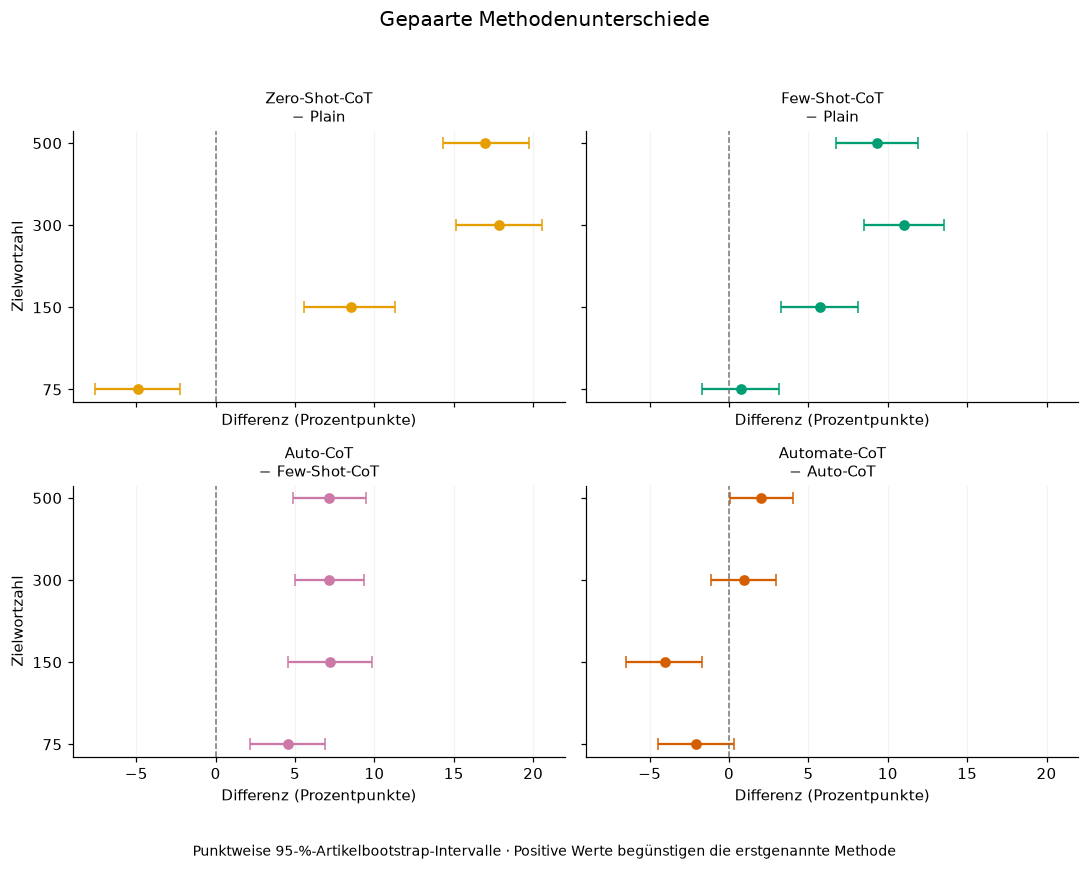

In [11]:
from faktenretention.statistics import contrasts_for
contrasts = contrasts_for(article)
assert len(contrasts) == 16 and contrasts.n_articles.eq(100).all()
export(contrasts, "vier_gepaarte_kontraste_pp_95ci")
contrast_table = contrasts.assign(Ergebnis=[f"{fmt(r.mean)} [{fmt(r.ci_low)}; {fmt(r.ci_high)}]; n={r.n_articles}" for r in contrasts.itertuples()])
contrast_table = contrast_table.pivot(index="contrast", columns="stage_target_words", values="Ergebnis").reindex(
    index=[f"{LABELS[a]} − {LABELS[b]}" for a,b in CONTRASTS], columns=STAGES)
display(contrast_table)
contrast_table.to_csv(OUT / "tabelle_kontraste_formatiert.csv")

fig, axes = plt.subplots(2,2,figsize=(10,8),sharey=True,sharex=True)
for ax,(first,second) in zip(axes.flat,CONTRASTS):
    sub=contrasts[(contrasts["first"]==first)&(contrasts.second==second)].set_index("stage_target_words").loc[STAGES]
    y=np.arange(4)
    ax.errorbar(sub["mean"],y,xerr=np.vstack([sub["mean"]-sub.ci_low,sub.ci_high-sub["mean"]]),
                fmt="o",color=COLORS[first],capsize=4,markersize=6)
    ax.axvline(0,color="#777777",linestyle="--",linewidth=1)
    ax.set_title(f"{LABELS[first]}\n− {LABELS[second]}",fontsize=10)
    ax.set_xlabel("Differenz (Prozentpunkte)");ax.grid(axis="x",alpha=.15)
for ax in axes[:,0]:
    ax.set(yticks=np.arange(4),yticklabels=STAGES,ylabel="Zielwortzahl")
axes[0,0].invert_yaxis()
fig.suptitle("Gepaarte Methodenunterschiede",fontsize=13)
fig.text(.5,.02,"Punktweise 95-%-Artikelbootstrap-Intervalle · Positive Werte begünstigen die erstgenannte Methode",fontsize=9,ha="center")
fig.tight_layout(rect=(0,.06,1,.95));savefig(fig,"02_gepaarte_kontraste")


## 6. Verteilungen auf Artikelebene

Die folgende Grafik zeigt die Faktenretention einzelner Artikel zwischen den Verfahren.

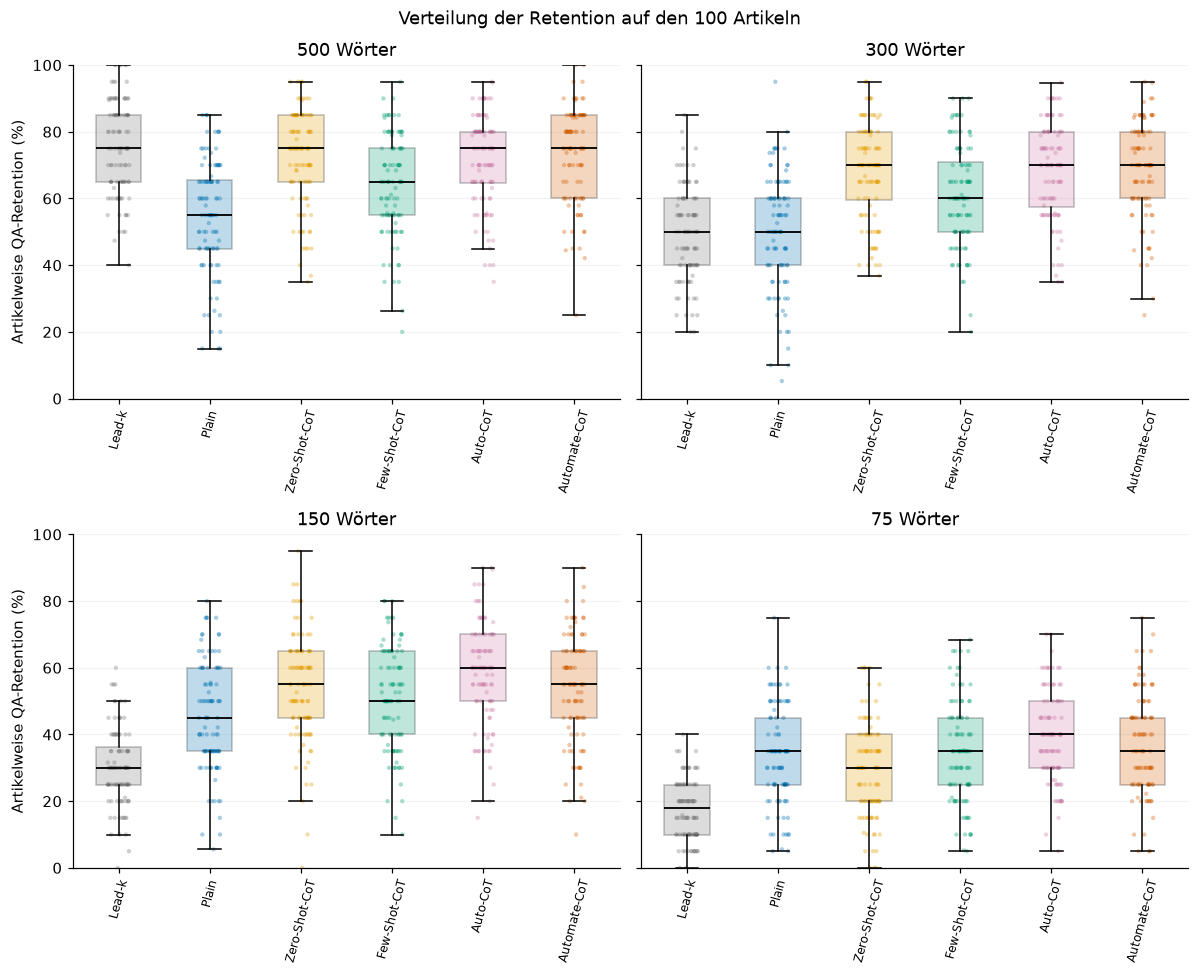

In [13]:
fig,axes=plt.subplots(2,2,figsize=(11,9),sharey=True)
jitter=np.random.default_rng(SEED).uniform(-.12,.12,size=len(IDS))
for ax,stage in zip(axes.flat,STAGES):
    arrays=[100*article[(article.method==m)&(article.stage_target_words==stage)].sort_values("article_id").retention_observed.to_numpy() for m in METHODS]
    boxes=ax.boxplot(arrays,positions=np.arange(6),widths=.5,patch_artist=True,showfliers=False,
                     medianprops={"color":"black","linewidth":1.2})
    for i,(method,values) in enumerate(zip(METHODS,arrays)):
        boxes["boxes"][i].set_facecolor(COLORS[method]);boxes["boxes"][i].set_alpha(.25)
        ax.scatter(i+jitter,values,s=8,color=COLORS[method],alpha=.35,edgecolors="none")
    ax.set(title=f"{stage} Wörter",xticks=np.arange(6),xticklabels=[LABELS[m] for m in METHODS],ylim=(0,100))
    ax.tick_params(axis="x",labelrotation=75,labelsize=8);ax.grid(axis="y",alpha=.15)
for ax in axes[:,0]:
    ax.set_ylabel("Artikelweise QA-Retention (%)")
fig.suptitle("Verteilung der Retention auf den 100 Artikeln")
fig.tight_layout();savefig(fig,"04_artikelverteilungen")


## 7. Diagnostik späterer Retentionsanstiege

Ein höherer Artikelwert in einer späteren Stufe kann durch andere QA-Antworten, lexikalische Varianten oder wechselnde gültige Nenner entstehen. Auf Faktenebene werden daher nur Übergänge mit **zwei gültigen Urteilen und ohne betroffene Generierungskette** verglichen. Ein Übergang von nicht-retained zu retained wird als *QA-Labelwechsel* dokumentiert. Er beweist weder, dass ein zuvor verlorenes Faktum sachlich zurückgewonnen wurde, noch dass der Text eine Halluzination enthält.

Die Tabelle unterscheidet wiederholte Übergangspositionen, unterschiedliche Artikel-Fakt-Paare und betroffene Artikel. Ausgewählte Fälle werden mit Frage, Referenz, beiden Antworten, Belegen und vollständigen Summary-Texten exportiert. So lassen sich wiederholte Bewertungen desselben zugrunde liegenden Fakts erkennen.

In [14]:
transition_rows=[];examples=[]
for before,after in TRANSITIONS[:3]:
    left=qa[qa.stage_target_words.eq(before)]
    right=qa[qa.stage_target_words.eq(after)]
    paired=left.merge(right,on=["article_id","method","canonical_fact_id"],suffixes=("_before","_after"),validate="one_to_one")
    paired["both_valid"]=paired.analysis_eligible_before & paired.analysis_eligible_after & ~paired.chain_failure_before & ~paired.chain_failure_after
    paired["upward"]=paired.both_valid & ~paired.retained_before & paired.retained_after
    paired["downward"]=paired.both_valid & paired.retained_before & ~paired.retained_after
    for method,sub in paired.groupby("method"):
        upward=sub[sub.upward]
        transition_rows.append({"method":method,"transition":f"{before}→{after}","n_fact_pairs":len(sub),
            "n_valid_fact_pairs":int(sub.both_valid.sum()),
            "n_generation_affected_pairs":int((sub.chain_failure_before | sub.chain_failure_after).sum()),"n_upward_label_changes":len(upward),
            "n_downward_label_changes":int(sub.downward.sum()),
            "n_unique_article_facts_upward":len(upward[["article_id","canonical_fact_id"]].drop_duplicates()),
            "n_articles_upward":upward.article_id.nunique()})
    upward=paired[paired.upward].copy();upward["transition"]=f"{before}→{after}"
    examples.append(upward[["article_id","method","canonical_fact_id","transition","question_before","reference_answer_before",
        "label_before","label_after","answer_before","answer_after","support_before","support_after","summary_before","summary_after"]])
transition_audit=pd.DataFrame(transition_rows)
upward_cases=pd.concat(examples,ignore_index=True)
export(transition_audit,"qa_labelwechsel_ueber_stufen")
export(upward_cases,"qa_labelwechsel_einzelfaelle")
display(transition_audit)
display(Markdown(f"**Anstiege auf Faktenebene:** {len(upward_cases)} Übergangspositionen betreffen "
    f"{len(upward_cases[['article_id','canonical_fact_id']].drop_duplicates())} unterschiedliche Originalfakten "
    f"in {upward_cases.article_id.nunique()} Artikeln. Mehrere Methoden/Stufen können dasselbe Faktum betreffen."))
display(upward_cases.sort_values(["article_id","canonical_fact_id","method","transition"]).head(10).drop(columns=["summary_before","summary_after"]))


,method,transition,n_fact_pairs,n_valid_fact_pairs,n_generation_affected_pairs,n_upward_label_changes,n_downward_label_changes,n_unique_article_facts_upward,n_articles_upward
0,auto_cot,500→300,2000,1984,0,24,88,24,20
1,automate_cot,500→300,2000,1979,0,28,114,28,24
2,few_shot_cot,500→300,2000,1980,0,23,82,23,19
3,lead_k,500→300,2000,1994,0,10,532,10,9
4,plain,500→300,2000,1986,0,26,122,26,22
5,zero_shot_cot,500→300,2000,1990,0,22,103,22,19
6,auto_cot,300→150,2000,1982,0,34,235,34,24
7,automate_cot,300→150,2000,1980,0,34,330,34,29
8,few_shot_cot,300→150,2000,1982,0,34,240,34,28
9,lead_k,300→150,2000,1994,0,9,393,9,9


**Anstiege auf Faktenebene:** 410 Übergangspositionen betreffen 290 unterschiedliche Originalfakten in 96 Artikeln. Mehrere Methoden/Stufen können dasselbe Faktum betreffen.

,article_id,method,canonical_fact_id,transition,question_before,reference_answer_before,label_before,label_after,answer_before,answer_after,support_before,support_after
110,1,few_shot_cot,1_F08,500→300,In which countries does Iran have strongholds?,"Syria, Iraq, Yemen and Lebanon",lost,retained,NOT_FOUND,Syria,,Assad’s Syria
0,1,auto_cot,1_F16,500→300,How many years after the assurances did North ...,Twelve years,lost,retained,NOT_FOUND,12,,"This echoes the 1994 U.S.-North Korea deal, wh..."
1,2,auto_cot,2_F09,500→300,Who holds the inside of Yarmouk?,anti-regime groups,reference_discordant,retained,al-Qaeda-linked Jabhat al-Nusra,anti-regime groups—including al-Qaeda-linked J...,"anti-regime groups—including, since ISIS withd...",anti-regime groups—including al-Qaeda-linked J...
249,2,few_shot_cot,2_F09,300→150,Who holds the inside of Yarmouk?,anti-regime groups,reference_discordant,retained,Jabhat al-Nusra,Anti-regime groups (now Jabhat al-Nusra),"anti-regime groups (now Jabhat al-Nusra, after...","Anti-regime groups (now Jabhat al-Nusra, after..."
283,2,automate_cot,2_F12,150→75,Which group was left in charge of the district...,Jabhat al-Nusra,lost,retained,NOT_FOUND,Jabhat al-Nusra,,al-Qaeda-linked Jabhat al-Nusra controls the i...
2,2,automate_cot,2_F18,500→300,Where are the shelters for displaced people lo...,government-controlled areas near the camp,reference_discordant,retained,government-controlled shelters nearby,government-controlled shelters,government-controlled shelters nearby,international aid groups like UNRWA assist onl...
133,3,zero_shot_cot,3_F01,300→150,Where is the Ringling Bros. Center for Elephan...,"Polk City, Florida",reference_discordant,retained,rural central Florida,Florida,a 200-acre facility in rural central Florida (...,a 200-acre Florida facility (halfway between O...
84,3,plain,3_F13,500→300,What is Wendy Kiso's profession?,research and conservation scientist,lost,retained,NOT_FOUND,scientist,,Scientists like Wendy Kiso use cryo-preservation
250,3,few_shot_cot,3_F15,300→150,What does the lab serve as for Asian elephants?,genetic resource bank,reference_discordant,retained,conservation hub,genetic resource bank,Asian elephant conservation hub,create a genetic resource bank
3,3,auto_cot,3_F17,500→300,Where was Mike born?,center's birthing barn,lost,retained,NOT_FOUND,on-site birthing barn,,2-year-old Mike from the on-site birthing barn


## 8. Paarweise Konfusionsmatrizen aller sechs Verfahren

Die Matrizen vergleichen **dieselben Artikel-Fakt-Stufen-Positionen** zwischen zwei Verfahren. Sechs Verfahren ergeben **15 unterschiedliche Paare**, jeweils bei 500, 300, 150 und 75 Zielwörtern. Zeilen stehen für das erstgenannte Verfahren, Spalten für das zweitgenannte. Ein umgekehrter Vergleich ist dieselbe Matrix transponiert.

**Keine Methode ist eine menschliche Referenz.** Die Diagonale zeigt übereinstimmende automatische Labels; eine hohe Übereinstimmung belegt keine hohe Faktenretention oder Richtigkeit. Auch zwei `lost`-Urteile stimmen überein. Die Matrizen ergänzen daher die bereits berichteten gepaarten Retentionsdifferenzen.

Die drei inhaltlichen Labels sind `retained`, `lost` und `reference_discordant`. Technisch fehlende QA-Urteile und Positionen in einer leeren Generierungskette werden im jeweiligen Paar **aus beiden Seiten gemeinsam ausgeschlossen**. Die verwendeten Nenner und ausgeschlossenen Positionen stehen in der Paarübersicht. Eine zusätzliche vollständige 5×5-Auditmatrix enthält die beiden technischen Kategorien separat; Generierungsfehler erhalten dabei Vorrang, wenn beide Fehlerarten auftreten.

Die kompakte 6×6-Übersicht zeigt die rohe Labelübereinstimmung in Prozent. Die detaillierten 3×3-Matrizen zeigen **absolute Häufigkeiten und zeilenbezogene Prozente**; der Nenner eines Prozentsatzes ist jeweils die Zeilensumme. Ihre Zellen sind beschreibende Häufigkeiten, keine unabhängigen Versuche. Die zusätzlich gepoolte Übersicht über alle Stufen zählt dieselben Originalfakten mehrfach und dient ausschließlich der deskriptiven Zusammenfassung.

In [24]:
from itertools import combinations
PAIRWISE_LABELS = ["retained", "lost", "reference_discordant"]
AUDIT_LABELS = PAIRWISE_LABELS + ["technical_missing", "generation_failure"]
METHOD_PAIRS = list(combinations(METHODS, 2))
assert len(METHOD_PAIRS) == 15
PAIR_KEY = ["article_id", "canonical_fact_id", "stage_target_words"]
pairwise_matrices = {}
pairwise_audit_matrices = {}
pairwise_records = []
count_records = []
audit_records = []

for first, second in METHOD_PAIRS:
    columns = PAIR_KEY + ["label", "technical_missing", "chain_failure"]
    left = qa.loc[qa.method.eq(first), columns]
    right = qa.loc[qa.method.eq(second), columns]
    matched = left.merge(right, on=PAIR_KEY, suffixes=("_first", "_second"),
                         validate="one_to_one", indicator=True)
    assert len(matched) == len(IDS) * N_FACTS * len(STAGES)
    assert matched["_merge"].eq("both").all()
    for stage in STAGES + ["all_stages"]:
        paired = matched if stage == "all_stages" else matched[matched.stage_target_words.eq(stage)]
        missing = paired.technical_missing_first | paired.technical_missing_second
        generation = paired.chain_failure_first | paired.chain_failure_second
        valid = ~(missing | generation)
        subset = paired[valid]
        matrix = pd.crosstab(subset.label_first, subset.label_second).reindex(
            index=PAIRWISE_LABELS, columns=PAIRWISE_LABELS, fill_value=0).astype(int)
        assert matrix.to_numpy().sum() == len(subset)
        assert np.array_equal(matrix.sum(axis=1).to_numpy(),
            subset.label_first.value_counts().reindex(PAIRWISE_LABELS, fill_value=0).to_numpy())
        assert np.array_equal(matrix.sum(axis=0).to_numpy(),
            subset.label_second.value_counts().reindex(PAIRWISE_LABELS, fill_value=0).to_numpy())
        reverse = pd.crosstab(subset.label_second, subset.label_first).reindex(
            index=PAIRWISE_LABELS, columns=PAIRWISE_LABELS, fill_value=0).astype(int)
        assert np.array_equal(matrix.to_numpy().T, reverse.to_numpy())
        pairwise_matrices[(first, second, stage)] = matrix
        same = int(np.trace(matrix.to_numpy()))
        record = {"first": first, "second": second, "stage": stage,
            "n_expected": len(paired), "n_valid_pairs": len(subset),
            "n_articles": subset.article_id.nunique(),
            "n_excluded_union": int((missing | generation).sum()),
            "n_technical_missing_either": int(missing.sum()),
            "n_generation_failure_either": int(generation.sum()),
            "n_both_failure_types": int((missing & generation).sum()),
            "n_same_label": same, "n_different_label": len(subset)-same,
            "agreement_percent": 100*same/len(subset) if len(subset) else np.nan}
        assert record["n_valid_pairs"] + record["n_excluded_union"] == record["n_expected"]
        pairwise_records.append(record)
        for row_label in PAIRWISE_LABELS:
            row_total = int(matrix.loc[row_label].sum())
            for col_label in PAIRWISE_LABELS:
                n = int(matrix.loc[row_label, col_label])
                count_records.append({"first": first, "second": second, "stage": stage,
                    "row_label": row_label, "column_label": col_label, "n": n,
                    "row_total": row_total, "row_percent": 100*n/row_total if row_total else np.nan,
                    "n_valid_pairs": len(subset)})
        audited_first = np.where(paired.chain_failure_first, "generation_failure", paired.label_first)
        audited_second = np.where(paired.chain_failure_second, "generation_failure", paired.label_second)
        full_matrix = pd.crosstab(pd.Series(audited_first), pd.Series(audited_second)).reindex(
            index=AUDIT_LABELS, columns=AUDIT_LABELS, fill_value=0).astype(int)
        assert full_matrix.to_numpy().sum() == len(paired)
        pairwise_audit_matrices[(first, second, stage)] = full_matrix
        for row_label in AUDIT_LABELS:
            for col_label in AUDIT_LABELS:
                audit_records.append({"first": first, "second": second, "stage": stage,
                    "row_label": row_label, "column_label": col_label,
                    "n": int(full_matrix.loc[row_label, col_label]), "n_expected": len(paired)})

pairwise_summary = pd.DataFrame(pairwise_records)
pairwise_counts = pd.DataFrame(count_records)
pairwise_audit_counts = pd.DataFrame(audit_records)
assert len(pairwise_summary) == 15 * 5
assert len(pairwise_counts) == 15 * 5 * 9
assert len(pairwise_audit_counts) == 15 * 5 * 25
for first, second in METHOD_PAIRS:
    assert np.array_equal(pairwise_matrices[(first, second, "all_stages")].to_numpy(),
        sum(pairwise_matrices[(first, second, stage)].to_numpy() for stage in STAGES))
export(pairwise_summary, "paarweise_labeluebereinstimmung_und_nenner")
export(pairwise_counts, "paarweise_konfusionsmatrizen_3x3")
export(pairwise_audit_counts, "paarweise_auditmatrizen_5x5")
summary_display = pairwise_summary[pairwise_summary.stage.eq("all_stages")].copy()
summary_display["Vergleich"] = summary_display["first"].map(LABELS) + " × " + summary_display.second.map(LABELS)
display(summary_display[["Vergleich", "n_valid_pairs", "n_excluded_union", "n_technical_missing_either",
                         "n_generation_failure_either", "agreement_percent"]].round(1))


,Vergleich,n_valid_pairs,n_excluded_union,n_technical_missing_either,n_generation_failure_either,agreement_percent
4,Lead-k × Plain,7952,48,48,0,57.5
9,Lead-k × Zero-Shot-CoT,7908,92,32,60,58.9
14,Lead-k × Few-Shot-CoT,7942,58,58,0,57.9
19,Lead-k × Auto-CoT,7950,50,50,0,56.9
24,Lead-k × Automate-CoT,7948,52,52,0,58.1
29,Plain × Zero-Shot-CoT,7884,116,56,60,70.4
34,Plain × Few-Shot-CoT,7922,78,78,0,72.5
39,Plain × Auto-CoT,7928,72,72,0,69.9
44,Plain × Automate-CoT,7927,73,73,0,69.4
49,Zero-Shot-CoT × Few-Shot-CoT,7875,125,65,60,74.3


### Kompakte Übersicht: Labelübereinstimmung für jedes Methodenpaar


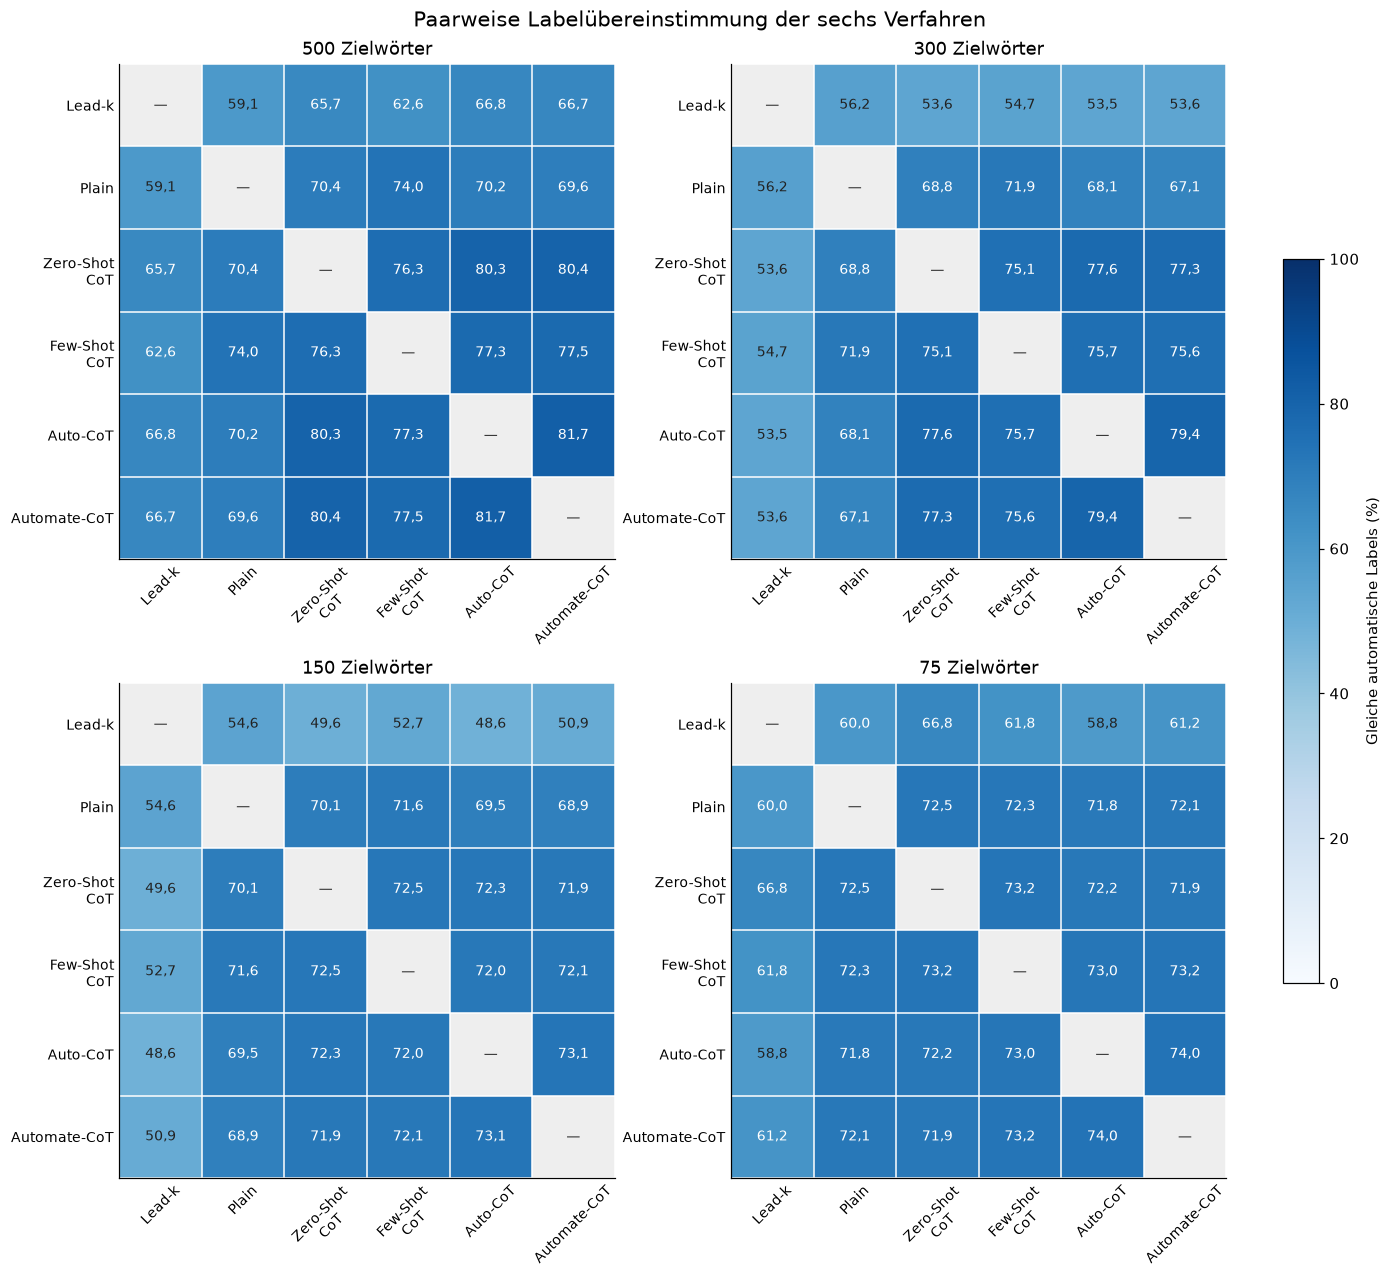

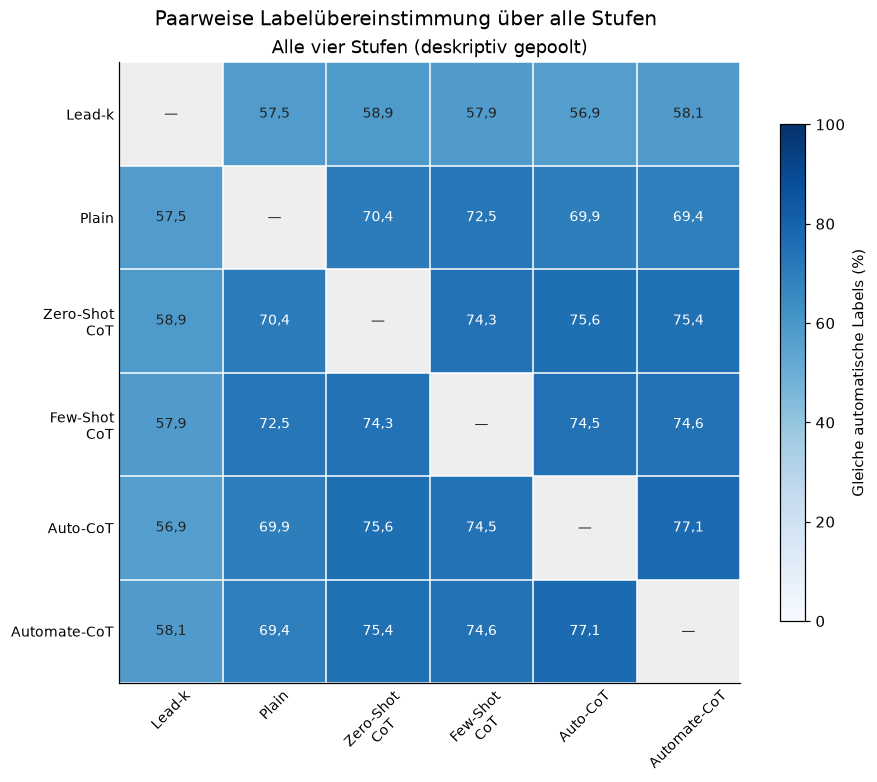

In [17]:
from matplotlib.colors import Normalize
PAIRWISE_CMAP = plt.colormaps["Blues"].copy()
PAIRWISE_CMAP.set_bad("#eeeeee")
method_ticks = ["Lead-k", "Plain", "Zero-Shot\nCoT", "Few-Shot\nCoT", "Auto-CoT", "Automate-CoT"]
agreement_matrices = {}
for stage in STAGES + ["all_stages"]:
    values = pd.DataFrame(np.nan, index=METHODS, columns=METHODS)
    for record in pairwise_summary[pairwise_summary.stage.eq(stage)].itertuples(index=False):
        values.loc[record.first, record.second] = record.agreement_percent
        values.loc[record.second, record.first] = record.agreement_percent
    assert np.allclose(values.to_numpy(), values.to_numpy().T, equal_nan=True)
    agreement_matrices[stage] = values
    values.rename(index=LABELS, columns=LABELS).to_csv(OUT / f"labeluebereinstimmung_6x6_{stage}.csv")

def plot_agreement(ax, stage):
    values = agreement_matrices[stage].to_numpy()
    img = ax.imshow(np.ma.masked_invalid(values), cmap=PAIRWISE_CMAP, vmin=0, vmax=100)
    for row in range(6):
        for col in range(6):
            v = values[row, col]
            ax.text(col, row, "—" if np.isnan(v) else fmt(v), ha="center", va="center",
                    fontsize=9, color="white" if np.isfinite(v) and v >= 60 else "#222222")
    ax.set(xticks=np.arange(6), yticks=np.arange(6), xticklabels=method_ticks, yticklabels=method_ticks)
    ax.tick_params(axis="both", labelsize=9, length=0)
    ax.tick_params(axis="x", labelrotation=45)
    ax.set_xticks(np.arange(-.5, 6, 1), minor=True)
    ax.set_yticks(np.arange(-.5, 6, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_title("Alle vier Stufen (deskriptiv gepoolt)" if stage == "all_stages" else f"{stage} Zielwörter")
    return img

fig, axes = plt.subplots(2, 2, figsize=(12.5, 11.5), layout="constrained")
for ax, stage in zip(axes.flat, STAGES):
    img = plot_agreement(ax, stage)
fig.colorbar(img, ax=axes.ravel().tolist(), shrink=.65, label="Gleiche automatische Labels (%)")
fig.suptitle("Paarweise Labelübereinstimmung der sechs Verfahren", fontsize=14)
savefig(fig, "06_labeluebereinstimmung_6x6_stufen")

fig, ax = plt.subplots(figsize=(8.5, 7), layout="constrained")
img = plot_agreement(ax, "all_stages")
fig.colorbar(img, ax=ax, shrink=.8, label="Gleiche automatische Labels (%)")
fig.suptitle("Paarweise Labelübereinstimmung über alle Stufen", fontsize=13)
savefig(fig, "07_labeluebereinstimmung_6x6_gepoolt")


### Detaillierte Konfusionsmatrizen: 15 Paare je Kompressionsstufe

Es folgt eine explorative Analyse aller möglichen Methodenpaar-Vergleiche und derer individueller Label übereinstimmungen. Diese Analyse ist explorativ und wird so nicht in der Arbeit thematisiert.

In [25]:
def plot_confusion_stage(stage):
    fig, axes = plt.subplots(3, 5, figsize=(17.5, 10.5), layout="constrained")
    for ax, (first, second) in zip(axes.flat, METHOD_PAIRS):
        matrix = pairwise_matrices[(first, second, stage)].to_numpy()
        totals = matrix.sum(axis=1, keepdims=True)
        percentages = np.divide(100*matrix, totals,
            out=np.full(matrix.shape, np.nan, dtype=float), where=totals > 0)
        img = ax.imshow(np.ma.masked_invalid(percentages), cmap=PAIRWISE_CMAP, vmin=0, vmax=100)
        for row in range(3):
            for col in range(3):
                pct = percentages[row, col]
                label = f"{matrix[row,col]}\n({fmt(pct)} %)" if np.isfinite(pct) else "–"
                ax.text(col, row, label, ha="center", va="center", fontsize=9,
                        color="white" if np.isfinite(pct) and pct >= 60 else "#222222")
        rec = pairwise_summary[(pairwise_summary["first"] == first) &
            (pairwise_summary.second == second) & (pairwise_summary.stage == stage)].iloc[0]
        ax.set_title(f"Zeile: {LABELS[first]}\nSpalte: {LABELS[second]}\n"
                     f"n = {rec.n_valid_pairs}; ausgeschlossen = {rec.n_excluded_union}", fontsize=9)
        ax.set(xticks=np.arange(3), yticks=np.arange(3), xticklabels=["R","L","D"], yticklabels=["R","L","D"])
        ax.tick_params(length=0, labelsize=10)
        ax.set_xticks(np.arange(-.5, 3, 1), minor=True)
        ax.set_yticks(np.arange(-.5, 3, 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=1)
        ax.tick_params(which="minor", bottom=False, left=False)
    fig.colorbar(img, ax=axes.ravel().tolist(), shrink=.6, label="Anteil innerhalb der Zeile (%)")
    fig.suptitle(f"15 paarweise Konfusionsmatrizen bei {stage} Zielwörtern\n"
                 "R = retained · L = lost · D = Referenzabweichung · Fallzahl und Zeilenprozent", fontsize=13)
    return fig


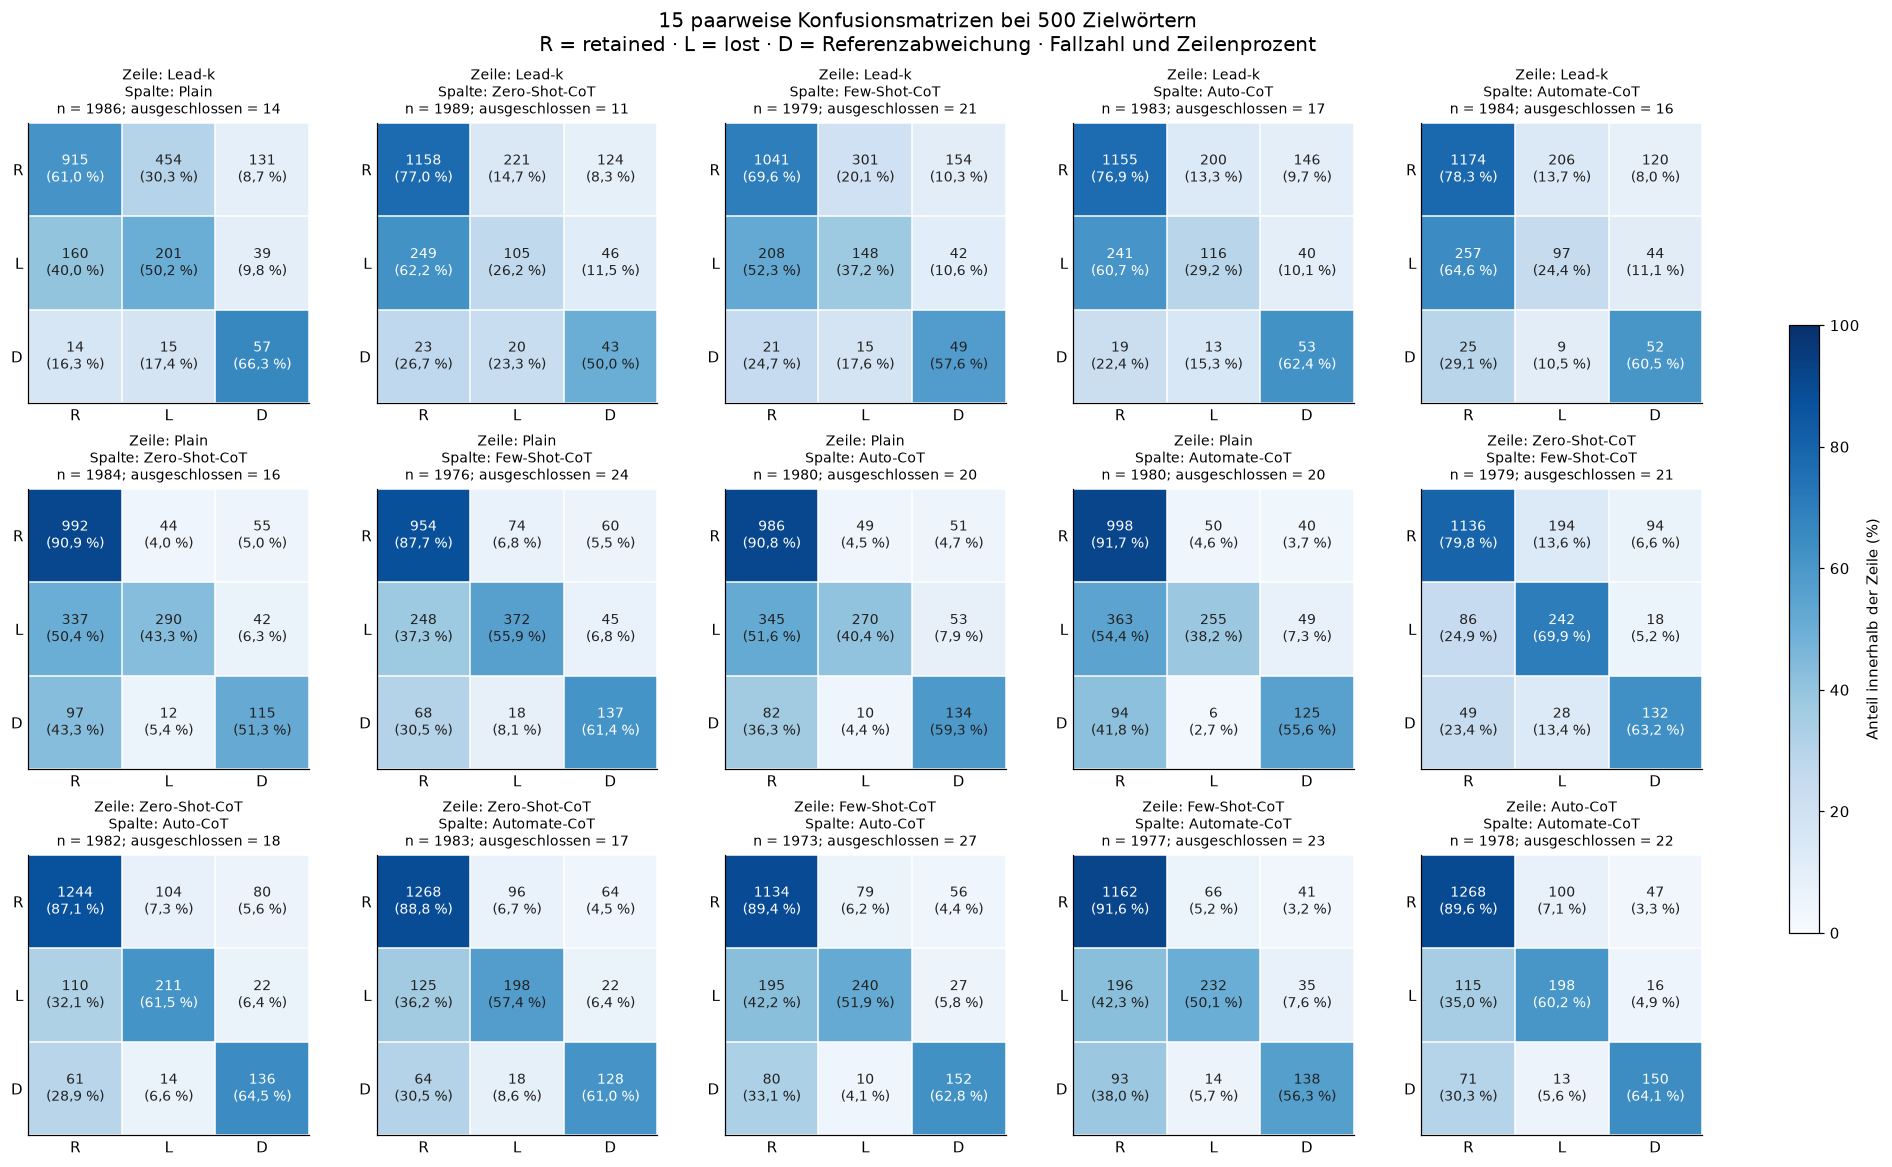

In [32]:
savefig(plot_confusion_stage(500), "08_konfusionsmatrizen_500")


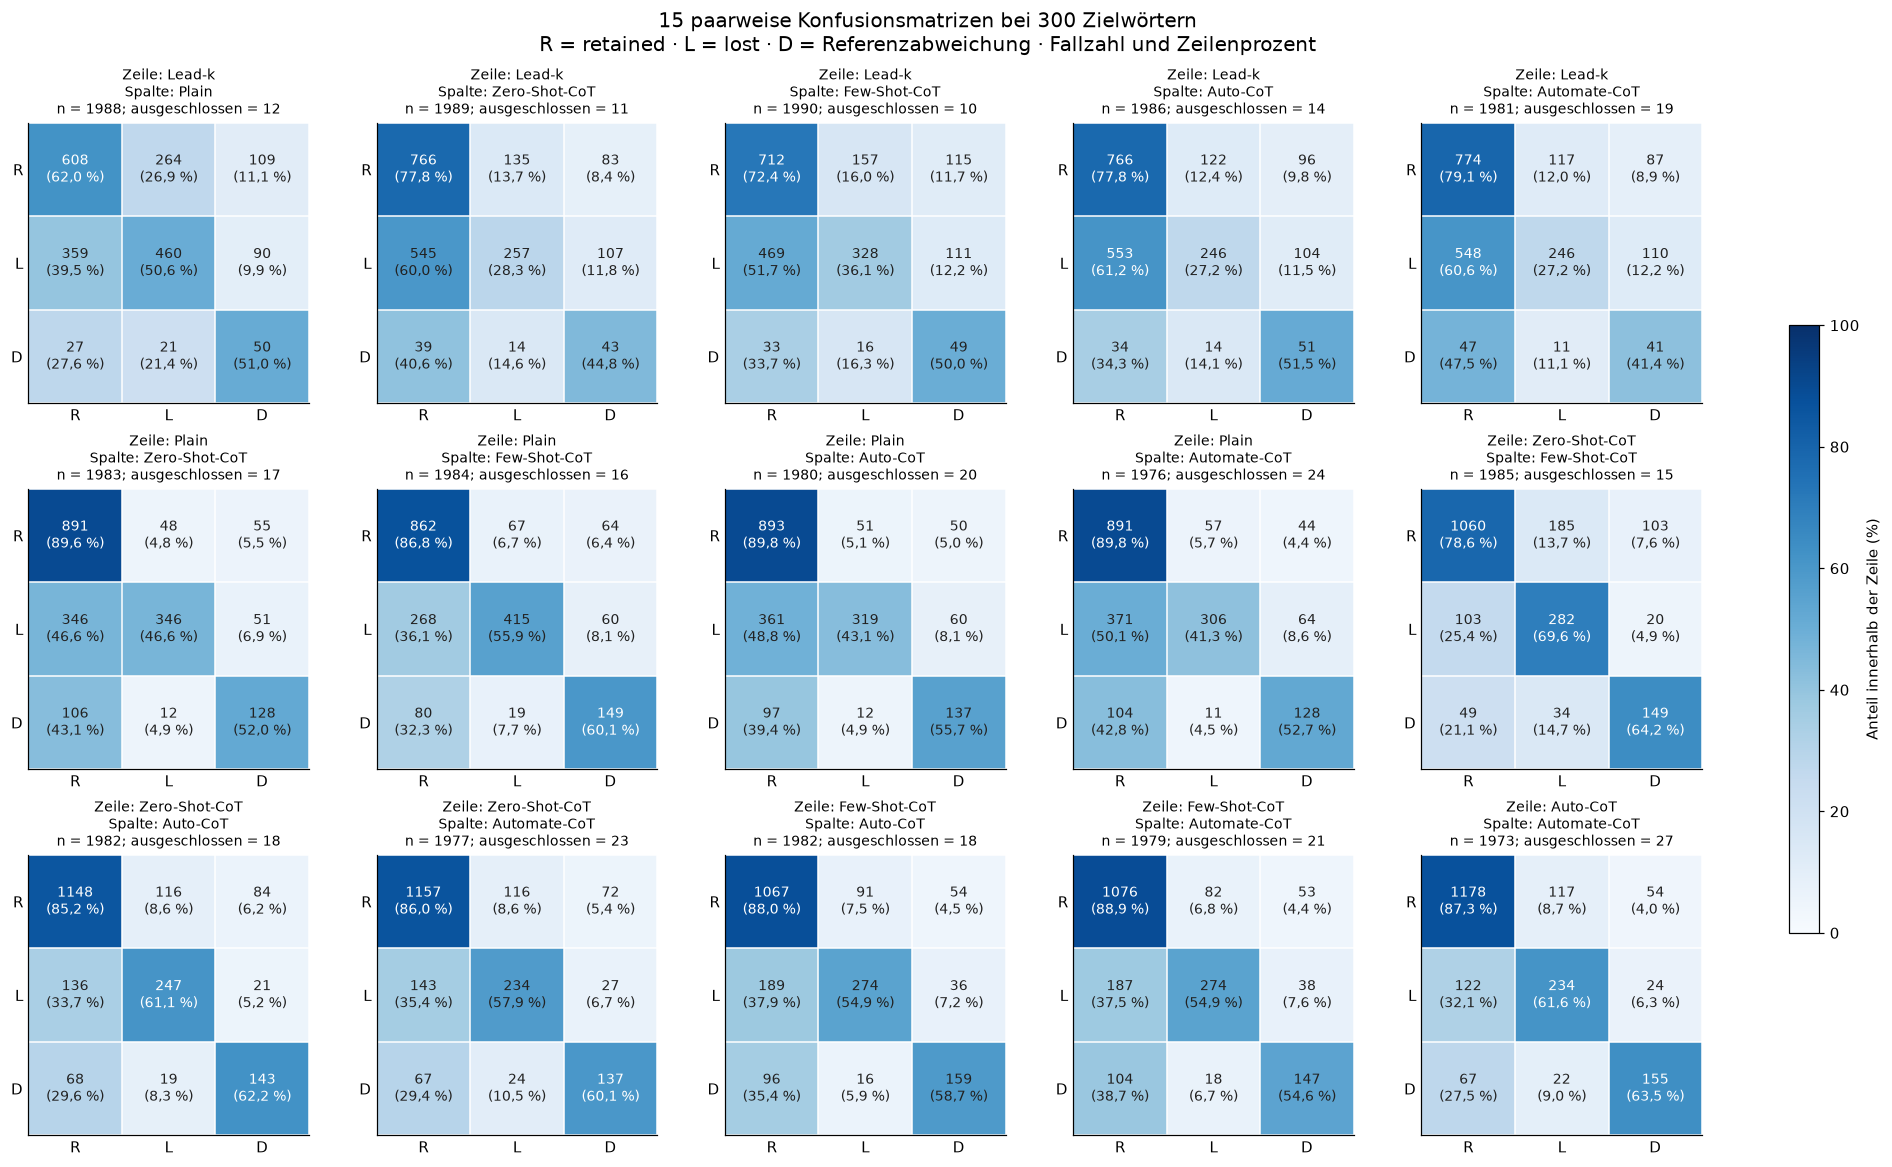

In [20]:
savefig(plot_confusion_stage(300), "08_konfusionsmatrizen_300")


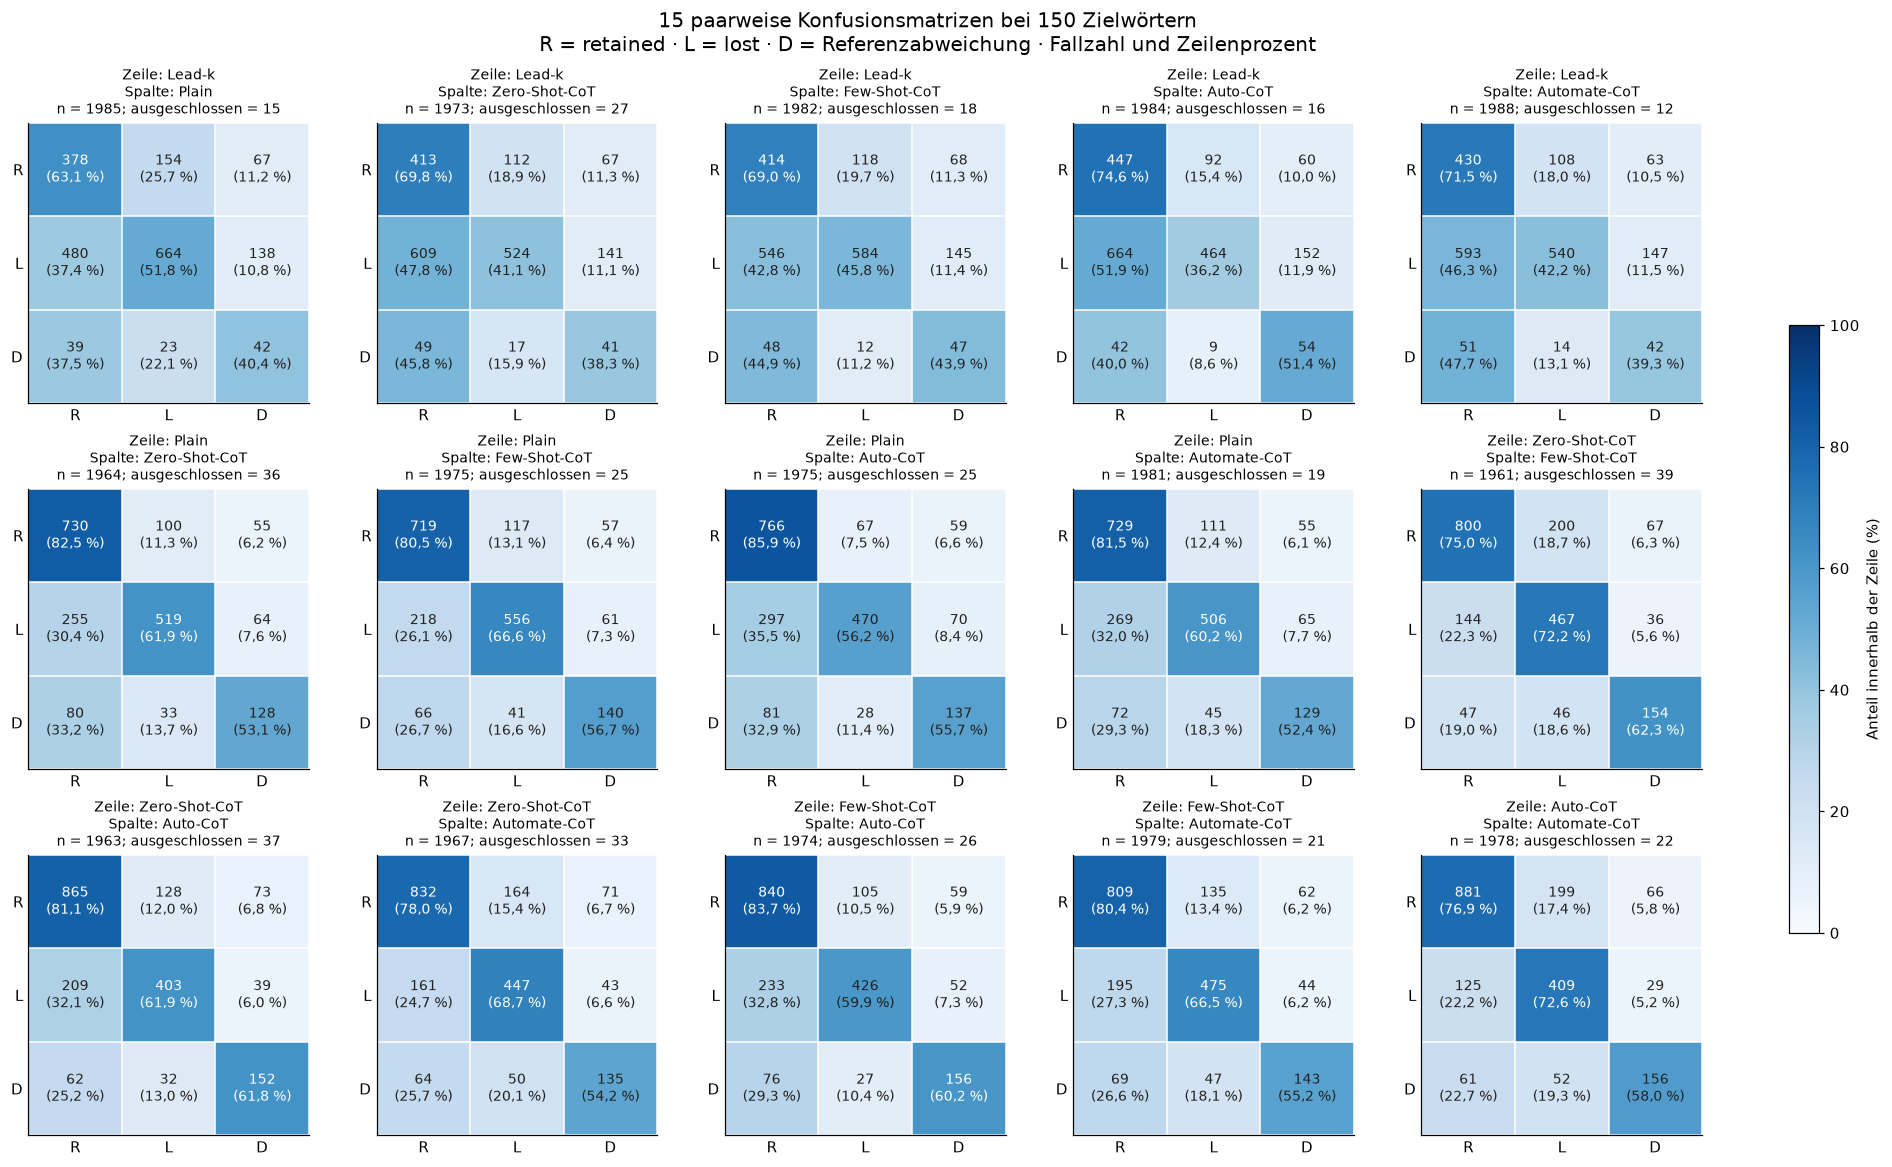

In [21]:
savefig(plot_confusion_stage(150), "08_konfusionsmatrizen_150")


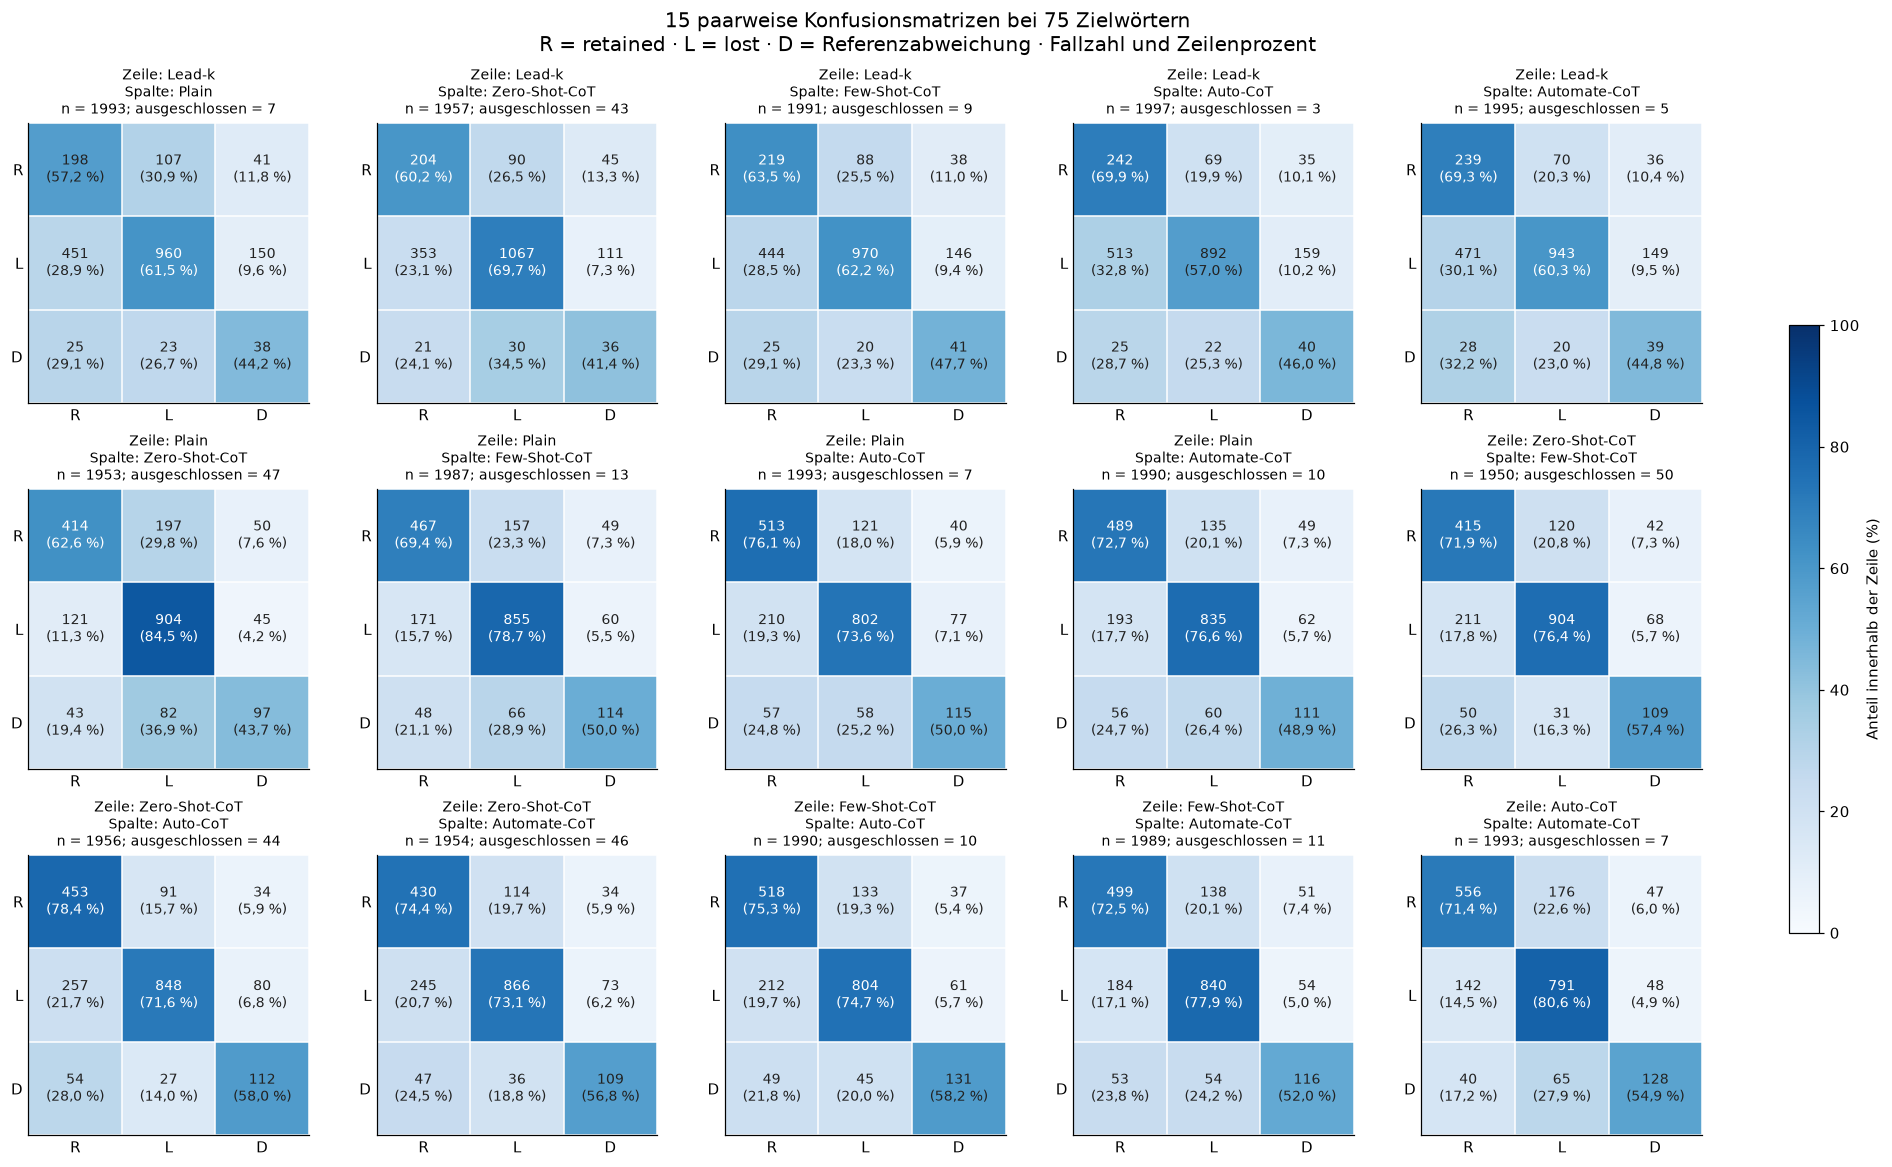

In [22]:
savefig(plot_confusion_stage(75), "08_konfusionsmatrizen_75")
